In [4]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, floor, when, lit

spark = SparkSession.builder.appName("MobileMoneyFraud").getOrCreate()
df = spark.read.csv("synthetic_mobile_money_transaction_dataset.csv", header=True, inferSchema=True)

df = (df.withColumn("hour", col("step") % 24)
        .withColumn("day", floor(col("step") / 24))
        .withColumn("is_night", when((col("hour") < 6) | (col("hour") >= 22), 1).otherwise(0))
        .withColumn("to_merchant", when(col("recipient").contains("-"), 1).otherwise(0))
        .withColumn("drain_ratio",
                    when(col("oldBalInitiator") > 0, col("amount") / col("oldBalInitiator"))
                    .otherwise(lit(1.0))))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/abijedidiah/spark_easter_2026/venv/lib64/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/31 16:15:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/31 16:15:44 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


In [5]:
df.select("amount", "hour", "is_night", "to_merchant", "oldBalInitiator", "drain_ratio", "isFraud").show(10)

+--------+----+--------+-----------+---------------+--------------------+-------+
|  amount|hour|is_night|to_merchant|oldBalInitiator|         drain_ratio|isFraud|
+--------+----+--------+-----------+---------------+--------------------+-------+
|19824.96|   0|       1|          0|      187712.18| 0.10561360482841337|      1|
|  598.97|   0|       1|          1|           8.92|   67.14910313901346|      0|
|  545.85|   0|       1|          1|           93.6|    5.83173076923077|      0|
|19847.01|   0|       1|          0|        -452.25|                 1.0|      1|
|  546.89|   0|       1|          1|      159148.76|0.003436344712959...|      0|
|16973.75|   0|       1|          0|      158601.88| 0.10702111475601676|      1|
|  659.02|   0|       1|          1|      261950.48|0.002515819020449972|      0|
|21103.99|   0|       1|          0|      261291.46| 0.08076800520001688|      1|
|  648.89|   0|       1|          1|        4808.94| 0.13493410190187444|      0|
|16908.07|   0| 

In [6]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

type_indexer = StringIndexer(inputCol="transactionType", outputCol="type_index")
df_feat = type_indexer.fit(df).transform(df)

type_encoder = OneHotEncoder(inputCols=["type_index"], outputCols=["type_onehot"])
df_feat = type_encoder.fit(df_feat).transform(df_feat)

feature_cols = ["amount", "hour", "is_night", "to_merchant",
                "oldBalInitiator", "oldBalRecipient", "drain_ratio", "type_onehot"]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_feat = assembler.transform(df_feat)

In [7]:
train, test = df_feat.randomSplit([0.8, 0.2], seed=42)

from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(labelCol="isFraud", featuresCol="features", maxIter=20)
lr_model = lr.fit(train)
preds = lr_model.transform(test)

preds.select("isFraud", "probability", "prediction").show(10, truncate=45)

26/10/31 16:15:53 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


+-------+------------------------------------------+----------+
|isFraud|                               probability|prediction|
+-------+------------------------------------------+----------+
|      0|[0.9999943474168703,5.6525831296783124E-6]|       0.0|
|      0| [0.9999943472355396,5.652764460406523E-6]|       0.0|
|      0|  [0.999994349272807,5.650727193051708E-6]|       0.0|
|      0| [0.9999943473800369,5.652619963103511E-6]|       0.0|
|      0|  [0.999994378381738,5.621618262008354E-6]|       0.0|
|      0| [0.9999943470098005,5.652990199500607E-6]|       0.0|
|      0| [0.9999943470259681,5.652974031877811E-6]|       0.0|
|      0| [0.9999943737879877,5.626212012277421E-6]|       0.0|
|      0|  [0.999994347447908,5.652552091950369E-6]|       0.0|
|      0|  [0.9999943492047362,5.65079526382295E-6]|       0.0|
+-------+------------------------------------------+----------+
only showing top 10 rows


# Random Forest, GBT, and the scorecard

In [8]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(labelCol="isFraud", featuresCol="features", numTrees=100, seed=42)
rf_model = rf.fit(train)
rf_preds = rf_model.transform(test)

26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_0 in memory! (computed 2.3 MiB so far)
26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_11 in memory! (computed 8.0 MiB so far)
26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_10 in memory! (computed 5.4 MiB so far)
26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_3 in memory! (computed 5.4 MiB so far)
26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_1 in memory! (computed 5.4 MiB so far)
26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_8 in memory! (computed 8.0 MiB so far)
26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_4 in memory! (computed 5.4 MiB so far)
26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_6 in memory! (computed 5.4 MiB so far)
26/10/31 16:16:24 WARN MemoryStore: Not enough space to cache rdd_250_2 in memory! (computed 8.0 MiB so far)
26/10/31 16:16:24

In [9]:
from pyspark.ml.classification import GBTClassifier

gbt = GBTClassifier(labelCol="isFraud", featuresCol="features", maxIter=20, seed=42)
gbt_model = gbt.fit(train)
gbt_preds = gbt_model.transform(test)

26/10/31 16:16:55 WARN MemoryStore: Not enough space to cache rdd_302_9 in memory! (computed 8.0 MiB so far)
26/10/31 16:16:55 WARN BlockManager: Persisting block rdd_302_9 to disk instead.


In [10]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

def scorecard(preds, name):
    binev = BinaryClassificationEvaluator(labelCol="isFraud", rawPredictionCol="rawPrediction")
    auc = binev.evaluate(preds)                                   # default = ROC-AUC
    pr  = binev.setMetricName("areaUnderPR").evaluate(preds)

    cm = {(int(r.isFraud), int(r.prediction)): r["count"]
          for r in preds.groupBy("isFraud", "prediction").count().collect()}
    tp = cm.get((1, 1), 0)   # fraud, caught
    fp = cm.get((0, 1), 0)   # legit, falsely accused
    fn = cm.get((1, 0), 0)   # fraud, missed
    tn = cm.get((0, 0), 0)   # legit, correctly cleared

    prec = tp / (tp + fp) if tp + fp else 0.0    # of the accused, how many guilty?
    rec  = tp / (tp + fn) if tp + fn else 0.0    # of the guilty, how many caught?
    f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0.0

    print(f"{name:15s} ROC-AUC={auc:.4f}  PR-AUC={pr:.4f}  fraud-P={prec:.4f}  fraud-R={rec:.4f}  fraud-F1={f1:.4f}")
    print(f"{'':15s} confusion:  TP={tp}  FP={fp}  FN={fn}  TN={tn}")

scorecard(preds, "LogisticReg")
scorecard(rf_preds, "RandomForest")
scorecard(gbt_preds, "GBT")

LogisticReg     ROC-AUC=0.8874  PR-AUC=0.3639  fraud-P=0.0000  fraud-R=0.0000  fraud-F1=0.0000
                confusion:  TP=0  FP=0  FN=35012  TN=308743


RandomForest    ROC-AUC=0.8879  PR-AUC=0.3899  fraud-P=0.7062  fraud-R=0.0437  fraud-F1=0.0823
                confusion:  TP=1529  FP=636  FN=33483  TN=308107


GBT             ROC-AUC=0.8890  PR-AUC=0.3982  fraud-P=0.6913  fraud-R=0.0764  fraud-F1=0.1376
                confusion:  TP=2674  FP=1194  FN=32338  TN=307549


In [11]:
from pyspark.sql.functions import col
from pyspark.ml.functions import vector_to_array

def threshold_sweep(preds, name):
    p1 = vector_to_array(col("probability"))[1]
    print(f"--- {name} ---")
    for t in [0.5, 0.2, 0.1, 0.05, 0.02]:
        cm = {(int(r.isFraud), int(r.p)): r["count"] for r in
              (preds.select("isFraud", (p1 >= t).cast("int").alias("p"))
                    .groupBy("isFraud", "p").count().collect())}
        tp, fp, fn = cm.get((1, 1), 0), cm.get((0, 1), 0), cm.get((1, 0), 0)
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec  = tp / (tp + fn) if tp + fn else 0.0
        f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        print(f"  thr={t:<5} fraud-P={prec:.3f}  fraud-R={rec:.3f}  fraud-F1={f1:.3f}   (caught {tp} of {tp + fn})")

threshold_sweep(preds, "LogisticReg")
threshold_sweep(rf_preds, "RandomForest")
threshold_sweep(gbt_preds, "GBT")

--- LogisticReg ---


  thr=0.5   fraud-P=0.000  fraud-R=0.000  fraud-F1=0.000   (caught 0 of 35012)


  thr=0.2   fraud-P=0.320  fraud-R=0.991  fraud-F1=0.483   (caught 34711 of 35012)


  thr=0.1   fraud-P=0.319  fraud-R=0.999  fraud-F1=0.483   (caught 34977 of 35012)


  thr=0.05  fraud-P=0.317  fraud-R=1.000  fraud-F1=0.481   (caught 35010 of 35012)


  thr=0.02  fraud-P=0.314  fraud-R=1.000  fraud-F1=0.478   (caught 35012 of 35012)
--- RandomForest ---


... (6 outputs left out)

  thr=0.2   fraud-P=0.319  fraud-R=0.998  fraud-F1=0.484   (caught 34952 of 35012)


  thr=0.1   fraud-P=0.318  fraud-R=1.000  fraud-F1=0.483   (caught 34999 of 35012)


  thr=0.05  fraud-P=0.318  fraud-R=1.000  fraud-F1=0.483   (caught 35008 of 35012)


  thr=0.02  fraud-P=0.102  fraud-R=1.000  fraud-F1=0.185   (caught 35012 of 35012)


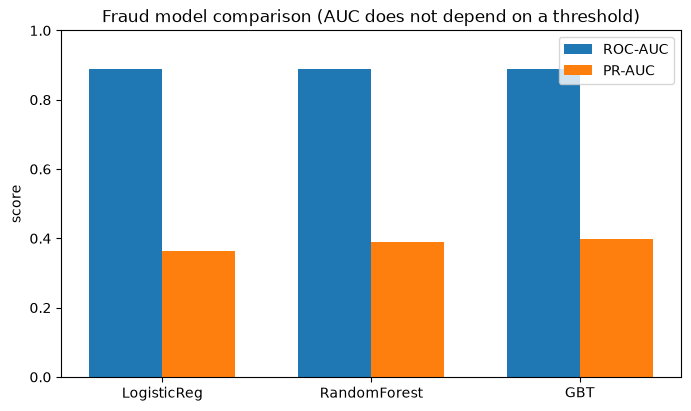

In [12]:
import matplotlib.pyplot as plt

models = ["LogisticReg", "RandomForest", "GBT"]
roc = [0.8874, 0.8879, 0.8890]
pr  = [0.3639, 0.3899, 0.3982]

x = range(len(models))
w = 0.35
plt.figure(figsize=(8, 4.5))
plt.bar([i - w/2 for i in x], roc, width=w, label="ROC-AUC", color="tab:blue")
plt.bar([i + w/2 for i in x], pr, width=w, label="PR-AUC", color="tab:orange")
plt.xticks(list(x), models)
plt.ylim(0, 1)
plt.ylabel("score")
plt.title("Fraud model comparison (AUC does not depend on a threshold)")
plt.legend()
plt.show()

## Check: where does fraud occur?

In [13]:
df.groupBy('transactionType', 'isFraud').count().orderBy('transactionType', 'isFraud').show()

+---------------+-------+------+
|transactionType|isFraud| count|
+---------------+-------+------+
|          DEBIT|      0|  5392|
|        DEPOSIT|      0|384431|
|        PAYMENT|      0|667245|
|       TRANSFER|      0|393810|
|       TRANSFER|      1|175518|
|     WITHDRAWAL|      0| 93785|
+---------------+-------+------+



In [14]:
names = ['amount','hour','is_night','to_merchant','oldBalInitiator','oldBalRecipient','drain_ratio'] + [f'type_{i}' for i in range(4)]
for n, v in sorted(zip(names, rf_model.featureImportances.toArray()), key=lambda x: -x[1]):
    print(f'{n:16s} {v:.3f}')

type_1           0.467
to_merchant      0.308
amount           0.087
type_0           0.041
oldBalRecipient  0.034
drain_ratio      0.029
oldBalInitiator  0.025
type_2           0.007
type_3           0.002
hour             0.000
is_night         0.000


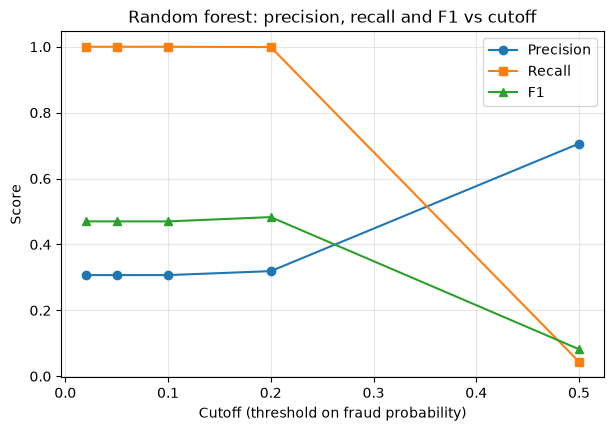

In [16]:
import matplotlib.pyplot as plt

cutoffs   = [0.5,  0.2,  0.1,  0.05, 0.02]
precision = [0.706, 0.319, 0.307, 0.307, 0.307]   
recall    = [0.044, 0.999, 1.000, 1.000, 1.000]
f1        = [0.082, 0.483, 0.470, 0.470, 0.470]

plt.figure(figsize=(7, 4.5))
plt.plot(cutoffs, precision, "o-", label="Precision")
plt.plot(cutoffs, recall, "s-", label="Recall")
plt.plot(cutoffs, f1, "^-", label="F1")
plt.xlabel("Cutoff (threshold on fraud probability)")
plt.ylabel("Score")
plt.title("Random forest: precision, recall and F1 vs cutoff")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("figure5_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
df.groupBy('transactionType', 'isFraud').count().orderBy('transactionType', 'isFraud').show()

+---------------+-------+------+
|transactionType|isFraud| count|
+---------------+-------+------+
|          DEBIT|      0|  5392|
|        DEPOSIT|      0|384431|
|        PAYMENT|      0|667245|
|       TRANSFER|      0|393810|
|       TRANSFER|      1|175518|
|     WITHDRAWAL|      0| 93785|
+---------------+-------+------+



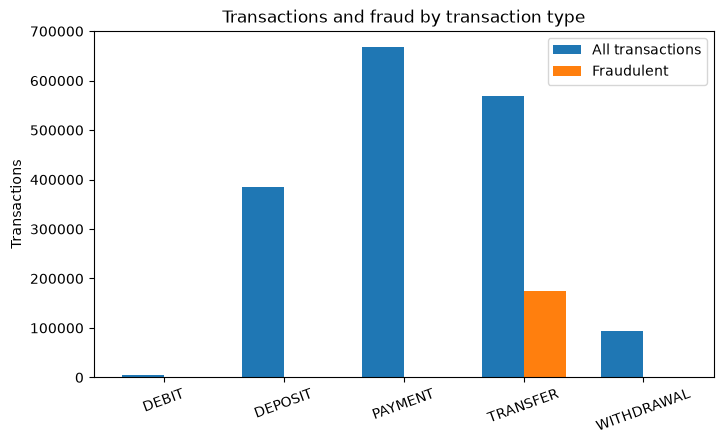

In [18]:
import numpy as np

rows = (df.groupBy('transactionType', 'isFraud').count().orderBy('transactionType').collect())
types = sorted({r['transactionType'] for r in rows})
total = {t: 0 for t in types}
fraud = {t: 0 for t in types}
for r in rows:
    total[r['transactionType']] += r['count']
    if r['isFraud'] == 1:
        fraud[r['transactionType']] = r['count']

x = np.arange(len(types)); w = 0.35
plt.figure(figsize=(8, 4.5))
plt.bar(x - w/2, [total[t] for t in types], width=w, label="All transactions")
plt.bar(x + w/2, [fraud[t] for t in types], width=w, label="Fraudulent")
plt.xticks(x, types, rotation=20)
plt.ylabel("Transactions")
plt.title("Transactions and fraud by transaction type")
plt.legend()
plt.savefig("figure1_type_fraud.png", dpi=150, bbox_inches="tight")
plt.show()